(quickstart)=
# Quick start: differential expression in bulk RNA-seq

This page runs a limma-voom analysis of simulated bulk RNA-seq counts from start to
finish: filtering genes by expression, TMM normalization factors, voom precision
weights, a design with named contrasts, a linear model for every gene, contrasts,
empirical Bayes moderation and adjusted p-values. Each step matches the R function
it mirrors, as the [Validation](validation.md) page shows; the one deliberate
difference here, exact standard errors for contrasts, is explained where it arises.
Because the counts are simulated, we know which genes truly changed, and the last
step checks the results against that truth.

The analysis runs in a few seconds. The first run in a new environment also compiles
CytePool's numerical routines, which takes longer once.

In [1]:
import matplotlib.pyplot as plt
import numba
import numpy as np

from cytepool.design import Design
from cytepool.normalization import (
    filter_by_expression,
    library_sizes,
    tmm_factors,
)
from cytepool.stats.empirical_bayes import moderated_statistics
from cytepool.stats.linear_models import contrasts_fit, fit_linear_model
from cytepool.stats.multiple_testing import adjust_p_values
from cytepool.stats.voom import voom

print("numpy", np.__version__, "and numba", numba.__version__)

numpy 2.5.4 and numba 0.68.0


## Simulate an experiment

Twelve samples: three treatments (control, drug A and drug B) with four replicates
each, sequenced in two batches that each hold two replicates of every treatment.
Data matrices in CytePool, such as counts and log expression values, are samples x
features, so the counts have one row per sample and one column per gene. Results of
the fits have one row per gene, as in limma.

The 6,000 genes have log-normal baseline abundances, so a minority of genes takes most
of the reads and many genes have only a few. Drug A changes 600 genes, up or down, by
0.6 to 2 on the log2 scale. Drug B shares 400 of those changes and makes 300 of its
own, mostly upwards; its extra reads go to those genes, so every other gene receives a
smaller share of drug B's libraries. Batch b2 shifts every gene by a small random
amount. Counts are negative binomial: gamma-distributed biological variation with a
coefficient of variation near 0.2, plus Poisson sampling. The libraries hold 2 to 5
million reads.

In [2]:
rng = np.random.default_rng(20261024)
n_genes = 6_000
treatments = np.array(["control", "drug_a", "drug_b"])
treatment = np.repeat(treatments, 4)
batch = np.tile(["b1", "b1", "b2", "b2"], 3)
genes = np.array([f"gene_{g:04d}" for g in range(n_genes)])

# Log-normal baseline abundance of each gene.
log2_abundance = rng.normal(0.0, 2.0, n_genes) / np.log(2.0)

# True log2 fold changes of drug A and drug B against control.
true_log2_fc = np.zeros((3, n_genes))
changed_by_a = rng.choice(n_genes, 600, replace=False)
signs = rng.choice([-1, 1], 600)
true_log2_fc[1, changed_by_a] = signs * rng.uniform(0.6, 2.0, 600)
shared = changed_by_a[:400]
true_log2_fc[2, shared] = true_log2_fc[1, shared]
unchanged_by_a = np.setdiff1d(np.arange(n_genes), changed_by_a)
changed_by_b = rng.choice(unchanged_by_a, 300, replace=False)
signs = rng.choice([-1, 1], 300, p=[0.2, 0.8])
true_log2_fc[2, changed_by_b] = signs * rng.uniform(0.6, 2.0, 300)

# Batch b2 shifts every gene by a small random amount.
batch_shift = rng.normal(0.0, 0.3, n_genes)

# Each library is shared out among the genes in proportion to their expression.
log2_expression = (
    log2_abundance
    + true_log2_fc[np.searchsorted(treatments, treatment)]
    + (batch == "b2")[:, None] * batch_shift
)
proportions = 2.0**log2_expression
proportions /= proportions.sum(axis=1, keepdims=True)
depth = rng.uniform(2e6, 5e6, treatment.size)
expected = depth[:, None] * proportions

# Negative binomial counts as gamma-Poisson mixtures.
dispersion = 0.04 * np.exp(rng.normal(0.0, 0.5, n_genes))
counts = rng.poisson(rng.gamma(1.0 / dispersion, expected * dispersion))

print(f"{counts.shape[0]} samples x {counts.shape[1]:,} genes")
print("library sizes (millions):", np.round(library_sizes(counts) / 1e6, 2))

12 samples x 6,000 genes


library sizes (millions): [3.41 4.67 2.12 4.02 2.32 4.25 4.55 2.79 4.45 4.99 2.22 3.11]


## Describe the design

A [`Design`](/api/designs.html#cytepool.design.Design) holds the sample table, the fixed effects as an R
formula, and the comparisons to test. The formula `~ 0 + treatment + batch` gives one
column per treatment, its mean log expression in batch b1, and one column for the
difference that batch b2 makes. Column names follow R's `model.matrix`. Named contrasts
are linear combinations of the columns, written as in limma's `makeContrasts`.

[`Design.check`](/api/designs.html#cytepool.design.Design.check) looks for problems that silently ruin an
analysis before anything is fitted: aliased columns, confounded factors, levels with a
single sample, contrasts that cannot be estimated and more.

In [3]:
design = Design(
    {"treatment": treatment, "batch": batch},
    "~ 0 + treatment + batch",
    contrasts={
        "drug_a_vs_control": "treatmentdrug_a - treatmentcontrol",
        "drug_b_vs_control": "treatmentdrug_b - treatmentcontrol",
        "drug_b_vs_drug_a": "treatmentdrug_b - treatmentdrug_a",
    },
)
print(design)
print(design.check())

Design: 12 samples x 4 columns, formula '~ 0 + treatment + batch'
  columns: treatmentcontrol, treatmentdrug_a, treatmentdrug_b, batchb2
  contrasts: drug_a_vs_control, drug_b_vs_control, drug_b_vs_drug_a
Design check: 12 samples, 4 columns, rank 4, 8 residual degrees of freedom; no problems found.


## Filter out genes with too few counts

Genes with only a few reads carry almost no information about differences between
treatments, and they distort the mean-variance trend that voom fits.
[`filter_by_expression`](/api/normalization.html#cytepool.normalization.filter_by_expression) applies edgeR's `filterByExpr`
rule: a gene is kept when it reaches 10 reads at the median library size
(proportionally more in larger libraries) in at least n samples, and 15 reads in
total. Given groups, n is the size of the smallest group. Given a design, it is the
inverse of the design's largest leverage: 3 here, a little less than the four
replicates of each treatment, because the batch effect is estimated from the same
samples.

In [4]:
keep = filter_by_expression(counts, design=design)
kept_counts = counts[:, keep]
kept_genes = genes[keep]
print(f"kept {keep.sum():,} of {n_genes:,} genes")

kept 5,294 of 6,000 genes


## Normalization factors

Library sizes account for sequencing depth, but not for composition: drug B's
upregulated genes take a larger share of its reads, so every other gene looks a little
lower in drug B. [`tmm_factors`](/api/normalization.html#cytepool.normalization.tmm_factors) computes edgeR's trimmed
mean of M values (TMM) factors, which scale the library sizes so that most genes do not
change between samples. Here they are computed from the genes that were kept. The
factors of the drug B samples are the smallest.

In [5]:
norm_factors = tmm_factors(kept_counts)
for sample in range(treatment.size):
    print(f"{treatment[sample]:<8} {batch[sample]}  {norm_factors[sample]:.3f}")

control  b1  1.049
control  b1  1.047
control  b2  1.023
control  b2  1.028
drug_a   b1  1.008
drug_a   b1  1.018
drug_a   b2  1.012
drug_a   b2  0.997
drug_b   b1  0.967
drug_b   b1  0.962
drug_b   b2  0.953
drug_b   b2  0.944


## Precision weights with voom

[`voom`](/api/voom.html#cytepool.stats.voom.voom) turns the counts into log2 counts per million, using
the library sizes times the normalization factors, and estimates how their variance
depends on the expression level: it fits the design to every gene, smooths the square
root of the residual standard deviations against the mean log count by LOWESS, and
gives each observation the inverse of its predicted variance as its weight. Low counts
are noisier on the log scale, so the trend decreases. Each local fit of the LOWESS
uses a fraction of the genes, the span, which voom chooses from the number of genes as
limma does and records in its result.

VoomResult(n_samples=12, n_features=5294, features_in_trend=5294, span=0.448)


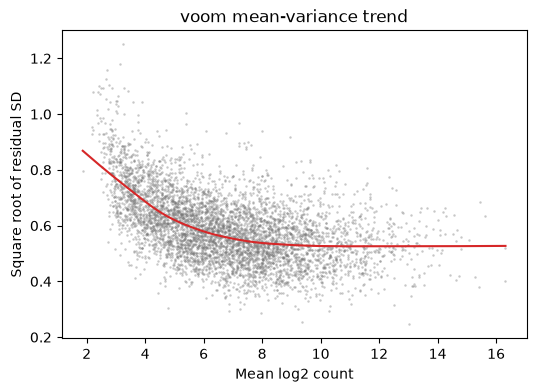

In [6]:
voom_result = voom(kept_counts, design, norm_factors=norm_factors)
print(voom_result)

# Plot each gene's square-root standard deviation against its mean log
# count, with the LOWESS trend that gives the weights.
order = np.argsort(voom_result.mean_log_count)
figure, axes = plt.subplots(figsize=(6, 4), dpi=100)
axes.scatter(
    voom_result.mean_log_count,
    voom_result.sqrt_sd,
    s=3,
    color="0.45",
    alpha=0.4,
    linewidths=0,
)
axes.plot(
    voom_result.mean_log_count[order],
    voom_result.sqrt_sd_trend[order],
    color="tab:red",
)
axes.set_xlabel("Mean log2 count")
axes.set_ylabel("Square root of residual SD")
axes.set_title("voom mean-variance trend")
plt.show()

## Fit a linear model to every gene

[`fit_linear_model`](/api/linear_models.html#cytepool.stats.linear_models.fit_linear_model) regresses the log2 counts per
million of each gene on the design by weighted least squares, with the voom weights,
as limma's `lmFit` does. Its coefficients are named after the design's columns.

In [7]:
fit = fit_linear_model(voom_result.log_cpm, design, weights=voom_result.weights)
print(fit.coefficient_names)
print("residual degrees of freedom:", fit.df_residual[0])

('treatmentcontrol', 'treatmentdrug_a', 'treatmentdrug_b', 'batchb2')
residual degrees of freedom: 8.0


## Contrasts

[`contrasts_fit`](/api/linear_models.html#cytepool.stats.linear_models.contrasts_fit) re-expresses every gene's fit in
terms of the named contrasts, as limma's `contrasts.fit` does: the coefficients become
log2 fold changes. By default, the standard error of each contrast comes from the
gene's own covariance matrix of the coefficients, which is exact. limma instead
combines the gene's standard errors with the correlations of the coefficients in the
design without weights. The two agree when one factorisation of the design serves
every gene (no missing values, and no weights or only sample weights) and for
contrasts of uncorrelated coefficients. Here voom's weights differ between genes and
the batch column correlates the treatment coefficients, so limma's standard errors
are approximate; `method="limma"` reproduces them.

In [8]:
contrast_fit = contrasts_fit(fit, design.contrasts)
print(contrast_fit.coefficient_names)

('drug_a_vs_control', 'drug_b_vs_control', 'drug_b_vs_drug_a')


## Empirical Bayes moderation

With eight residual degrees of freedom, each gene's variance is poorly estimated on
its own. [`moderated_statistics`](/api/empirical_bayes.html#cytepool.stats.empirical_bayes.moderated_statistics) estimates a prior
distribution of the variances from all genes and replaces each gene's variance by a
weighted average of that variance and the prior variance, with their degrees of
freedom as weights (limma's `eBayes` and its posterior variances). The moderated
t-statistics have the residual and the prior degrees of freedom combined.

In [9]:
moderated = moderated_statistics(contrast_fit)
print(f"prior degrees of freedom: {moderated.prior_df:.2f}")
print(f"prior variance: {moderated.prior_variance:.4f}")

prior degrees of freedom: 13.46
prior variance: 0.9854


## Adjusted p-values and top genes

[`adjust_p_values`](/api/multiple_testing.html#cytepool.stats.multiple_testing.adjust_p_values) with the Benjamini-Hochberg
method controls the false discovery rate. `axis=0` adjusts each contrast (each column)
as its own family of tests, as limma's `topTable` does for one coefficient.

In [10]:
fdr = adjust_p_values(moderated.p_value, "bh", axis=0)
log2_fc = contrast_fit.coefficients
for j, name in enumerate(contrast_fit.coefficient_names):
    significant = fdr[:, j] < 0.05
    up = np.count_nonzero(significant & (log2_fc[:, j] > 0))
    down = np.count_nonzero(significant & (log2_fc[:, j] < 0))
    print(f"{name}: {up + down} genes at 5% FDR, {up} up and {down} down")

drug_a_vs_control: 462 genes at 5% FDR, 256 up and 206 down
drug_b_vs_control: 555 genes at 5% FDR, 380 up and 175 down
drug_b_vs_drug_a: 386 genes at 5% FDR, 258 up and 128 down


The genes with the smallest p-values for drug A against control, with the columns of
limma's `topTable`: the log2 fold change, the mean log2 CPM, the moderated
t-statistic, its p-value, the adjusted p-value and the B-statistic (the log-odds that
the gene changed). This is the order of `topTable(sort.by = "P")`; by default
`topTable` sorts by B, which can order genes with different weights slightly
differently.

In [11]:
j = contrast_fit.coefficient_names.index("drug_a_vs_control")
top = np.argsort(moderated.p_value[:, j])[:10]
columns = {
    "logFC": log2_fc[top, j],
    "AveExpr": fit.mean_expression[top],
    "t": moderated.t[top, j],
    "P.Value": moderated.p_value[top, j],
    "adj.P.Val": fdr[top, j],
    "B": moderated.lods[top, j],
}
print(f"{'gene':<10}" + "".join(f"{name:>10}" for name in columns))
for row, g in enumerate(top):
    values = "".join(f"{column[row]:>10.3g}" for column in columns.values())
    print(f"{kept_genes[g]:<10}{values}")

gene           logFC   AveExpr         t   P.Value adj.P.Val         B
gene_3774       2.68      6.96        13  1.28e-11  6.77e-08      16.7
gene_1529       2.11      6.43      12.2  3.85e-11  1.02e-07      15.6
gene_0118       1.99      11.4      11.9  6.47e-11  1.14e-07      15.2
gene_0744       2.25      9.19      11.5  1.18e-10  1.56e-07      14.6
gene_1858       2.26      5.98      11.2  1.92e-10  1.62e-07      14.1
gene_4276       1.93      10.2      11.1  2.29e-10  1.62e-07      13.9
gene_5034      -2.29       5.9     -11.1  2.31e-10  1.62e-07      13.9
gene_2462       1.77      10.7        11  2.56e-10  1.62e-07      13.8
gene_4195       1.97      8.52        11  2.75e-10  1.62e-07      13.7
gene_4928       2.26      4.92      10.7  4.57e-10  2.31e-07      13.2


## Compare with the truth

The simulation knows which genes changed in each comparison. At a 5% false discovery
rate, the share of discoveries that are false should be about 5% or less, and most of
the genes that changed should be found.

In [12]:
truth = {
    "drug_a_vs_control": true_log2_fc[1] - true_log2_fc[0],
    "drug_b_vs_control": true_log2_fc[2] - true_log2_fc[0],
    "drug_b_vs_drug_a": true_log2_fc[2] - true_log2_fc[1],
}
for j, name in enumerate(contrast_fit.coefficient_names):
    changed = truth[name][keep] != 0
    found = fdr[:, j] < 0.05
    true_found = np.count_nonzero(found & changed)
    false_found = np.count_nonzero(found & ~changed)
    print(
        f"{name}: found {true_found} of {changed.sum()} changed genes; "
        f"{false_found} of {found.sum()} discoveries are false "
        f"({false_found / max(found.sum(), 1):.1%})"
    )

drug_a_vs_control: found 441 of 544 changed genes; 21 of 462 discoveries are false (4.5%)
drug_b_vs_control: found 535 of 636 changed genes; 20 of 555 discoveries are false (3.6%)
drug_b_vs_drug_a: found 372 of 458 changed genes; 14 of 386 discoveries are false (3.6%)


## The same analysis in R

Each step corresponds to an edgeR or limma function. R stores genes in rows, so its
count matrix is the transpose of the one used here. Library sizes are the totals of
the genes that were kept, in both.

| Step | CytePool | R |
| --- | --- | --- |
| Filter genes | `keep = filter_by_expression(counts, design=design)`, then `counts[:, keep]` | `keep <- filterByExpr(y, design)`, then `y[keep, , keep.lib.sizes = FALSE]` |
| Normalization factors | `tmm_factors(counts)` | `calcNormFactors(y)` |
| Design and contrasts | `Design(samples, "~ 0 + treatment + batch", contrasts=...)` | `model.matrix(~ 0 + treatment + batch)` and `makeContrasts(...)` |
| Precision weights | `voom(counts, design, norm_factors=factors)` | `voom(y, design)` in limma 3.66 or later, `voom(y, design, adaptive.span = TRUE)` in 3.60 to 3.65 |
| Linear models | `fit_linear_model(v.log_cpm, design, weights=v.weights)` | `lmFit(v, design)` |
| Contrasts | `contrasts_fit(fit, design.contrasts, method="limma")` | `contrasts.fit(fit, contrasts)` |
| Moderation | `moderated_statistics(fit)` | `eBayes(fit)` |
| Adjusted p-values | `adjust_p_values(p, "bh", axis=0)` | `topTable(fit, coef = j, sort.by = "P")`, which adjusts by BH |

`moderated_statistics` uses limma's moment estimator of the prior, which `eBayes`
uses by default whenever all genes have the same residual degrees of freedom, as
here. The [API reference](/api/index.html) documents every function, and the
[Validation](validation.md) page shows how closely each one agrees with R.